# Does what drives gaze change over the course of free viewing?
*An exploratory analysis of COCO-FreeView*

**Question.** In 5-second free viewing of natural scenes, are early fixations better explained by low-level
feature contrast, and later fixations by objects? This touches the idea that bottom-up saliency (for example,
the V1 saliency hypothesis, Li 2002) dominates fast, early orienting, while object- and meaning-level factors
take over with time.

**Approach.** For each fixation index *k* we score three maps at the fixated location (NSS):

| map | what it stands for |
|---|---|
| **center** | where people look on *any* image (empirical, built from the other half of images) |
| **contrast** | a simple low-level feature-contrast baseline: intensity, colour opponency, orientation |
| **objects** | COCO object masks |

and we measure how often fixation *k* lands on an annotated object.

**The control that matters.** Every number is shown next to a *shuffled* version: the same map scored at
fixations recorded on a *different* image. Natural images put objects and contrast near the middle, and people
look near the middle, so raw scores mix "image-specific guidance" with "center bias". Only the gap between
own and shuffled is evidence that the image itself guided gaze.

**Scope.** Exploratory. The contrast map is a transparent baseline, **not** a model of V1. Use train/validation
fixations only.

### Data you need (not included; the dataset terms forbid redistribution)
1. Fixations: `COCOFreeView_fixations_trainval.json` (COCO-FreeView page)
2. Stimuli: the COCO-Search18 TP and TA image sets (1680x1050), unzipped anywhere under `data/stimuli/`
3. Object annotations: COCO 2017 `instances_train2017.json` and `instances_val2017.json` in `data/annotations/`

See `README.md` for links.

## 0 · Setup

In [1]:
import glob, os, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import fvtools as fv

DATA_DIR   = os.environ.get("FV_DATA_DIR", "data")
FIX_JSON   = os.path.join(DATA_DIR, "COCOFreeView_fixations_trainval.json")
STIM_DIR   = os.path.join(DATA_DIR, "stimuli")
ANN_FILES  = sorted(glob.glob(os.path.join(DATA_DIR, "annotations", "instances_*2017.json")))

N_IMAGES   = int(os.environ.get("FV_N_IMAGES", 0))  # start small; set to 0 for all images
DROP_FIRST = True     # fixation 0 is usually the central start dot (checked in section 1)
MAX_IDX    = 12       # analyse fixations 1..MAX_IDX (later indices have few scanpaths)
COMBINE    = "max"    # how contrast channels combine: "max" (V1SH-style) or "mean" (Itti-Koch-style)
PX_PER_DEG = None     # set from the dataset README/paper to report saccades in degrees
SEED       = 0

# Robustness switches: re-run the notebook with these changed and compare figures
MAX_OBJ_FRAC = None   # e.g. 0.5 drops images where one object covers > 50% (pizza-style images)
N_BOOT_JOINT = 300    # bootstrap samples for the joint regression (lower it for a quick run)
TAG = f"{COMBINE}" + (f"_maxobj{MAX_OBJ_FRAC}" if MAX_OBJ_FRAC else "")  # appended to figure names
os.makedirs("figures", exist_ok=True); os.makedirs("cache", exist_ok=True)

# chart style: recessive axes, thin lines, fixed colour per map
C = {"objects": "#2a78d6", "contrast": "#eb6834", "center": "#1baf7a"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "lines.linewidth": 2, "legend.frameon": False,
})

def ci_line(ax, d, color, label, dashed=False, end_label=True):
    ls = "--" if dashed else "-"
    ax.plot(d.idx, d["mean"], ls, color=color, marker="o", ms=4, label=label)
    ax.fill_between(d.idx, d.lo, d.hi, color=color, alpha=0.15 if not dashed else 0.08, lw=0)
    if end_label:
        ax.annotate(label, (d.idx.iloc[-1], d["mean"].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", color=INK2, fontsize=9)
print("annotation files:", ANN_FILES)

annotation files: ['data/annotations/instances_train2017.json', 'data/annotations/instances_val2017.json']


## 1 · Load fixations and check the first fixation

In [2]:
raw = fv.load_fixations(FIX_JSON)
raw, frame = fv.to_stimulus_frame(raw)
raw = fv.add_saccades(raw, PX_PER_DEG)   # amplitudes computed before any fixation is dropped
lens = raw.groupby("scan").size()
print(f"coordinate frame detected: {frame}")
print(f"{raw.scan.nunique():,} scanpaths · {raw.image.nunique():,} images · "
      f"{raw.subject.nunique()} subjects · {len(raw):,} fixations")
print(f"fixations per scanpath: median {lens.median():.0f}, IQR {lens.quantile(.25):.0f}-{lens.quantile(.75):.0f}")
print("splits:", raw.split.value_counts(dropna=False).to_dict())

coordinate frame detected: 1680x1050
43,048 scanpaths · 4,317 images · 10 subjects · 665,005 fixations
fixations per scanpath: median 16, IQR 14-18
splits: {'train': 572184, 'valid': 92821}


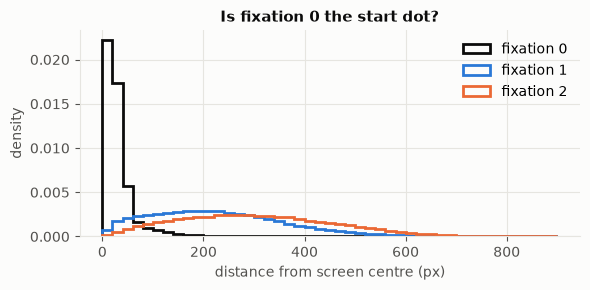

median distance from centre by index: {0: 22.0, 1: 215.0, 2: 295.0, 3: 311.0}


In [3]:
# Trials start with a central fixation dot. If fixation 0 sits on the screen centre, it reflects
# the task, not the image, and should be dropped.
dist = np.hypot(raw.x - fv.STIM_W / 2, raw.y - fv.STIM_H / 2)
fig, ax = plt.subplots(figsize=(6, 3))
bins = np.linspace(0, 900, 46)
for k, col in [(0, INK), (1, C["objects"]), (2, C["contrast"])]:
    ax.hist(dist[raw.idx == k], bins=bins, histtype="step", lw=2, color=col, density=True, label=f"fixation {k}")
ax.set(xlabel="distance from screen centre (px)", ylabel="density", title="Is fixation 0 the start dot?")
ax.legend(); plt.tight_layout(); plt.savefig("figures/00_first_fixation.png", dpi=160); plt.show()
print("median distance from centre by index:", dist.groupby(raw.idx).median().head(4).round(0).to_dict())

## 2 · Match images, annotations and stimuli

In [4]:
stim_index = fv.index_stimuli(STIM_DIR)
coco = fv.CocoIndex(ANN_FILES)
images = sorted(set(raw.image) & set(stim_index) & set(coco.by_name))
print(f"images with fixations: {raw.image.nunique():,} · with stimulus file: "
      f"{len(set(raw.image) & set(stim_index)):,} · usable (also annotated): {len(images):,}")

rng = np.random.default_rng(SEED)
if N_IMAGES and N_IMAGES < len(images):
    images = sorted(rng.choice(images, N_IMAGES, replace=False))

fix = raw[raw.image.isin(images)]
if DROP_FIRST:
    fix = fix[fix.idx >= 1]
by_image = dict(tuple(fix.groupby("image")))
cmaps = fv.center_maps(fix, images, seed=SEED)

# shuffled control: each image is scored at fixations from one other image (a derangement)
perm = list(rng.permutation(images))
donor = {perm[i]: perm[(i + 1) % len(perm)] for i in range(len(perm))}
print(f"analysing {len(images):,} images, {len(fix):,} fixations")

loading annotations into memory...
Done (t=40.15s)
creating index...
index created!
loading annotations into memory...
Done (t=0.77s)
creating index...
index created!
images with fixations: 4,317 · with stimulus file: 4,317 · usable (also annotated): 4,317
analysing 4,317 images, 621,957 fixations


## 3 · Score every fixation (cached)

In [5]:
cache = f"cache/scored_v2_n{len(images)}_{COMBINE}_drop{int(DROP_FIRST)}_s{SEED}.pkl"
if os.path.exists(cache):
    own, shuf, info = pd.read_pickle(cache)
else:
    own_l, shuf_l, info_l, t0 = [], [], [], time.time()
    for i, name in enumerate(images):
        stim = np.asarray(Image.open(stim_index[name]).convert("RGB"))
        if stim.shape[:2] != (fv.STIM_H, fv.STIM_W):
            stim = np.asarray(Image.fromarray(stim).resize((fv.STIM_W, fv.STIM_H)))
        o, s, inf = fv.score_image(name, stim, coco, by_image[name], by_image[donor[name]],
                                   cmaps[name], combine=COMBINE)
        own_l.append(o); shuf_l.append(s); info_l.append(inf)
        if (i + 1) % 100 == 0:
            print(f"  {i + 1}/{len(images)} images · {time.time() - t0:.0f}s")
    own, shuf, info = pd.concat(own_l), pd.concat(shuf_l), pd.DataFrame(info_l)
    pd.to_pickle((own, shuf, info), cache)
own = own[own.idx <= MAX_IDX]; shuf = shuf[shuf.idx <= MAX_IDX]
print(f"{len(own):,} own fixations · {len(shuf):,} shuffled-control fixations")

# Robustness filter: drop images dominated by a single object (applied after caching)
print(f"largest single object: median {info.max_obj_frac.median():.0%} of the image; "
      f"{(info.max_obj_frac > 0.5).mean():.0%} of images have one object covering > 50%")
if MAX_OBJ_FRAC:
    keep = set(info.loc[info.max_obj_frac <= MAX_OBJ_FRAC, "image"])
    own, shuf = own[own.map_image.isin(keep)], shuf[shuf.map_image.isin(keep)]
    if len(keep) < 30:
        raise ValueError(f"MAX_OBJ_FRAC={MAX_OBJ_FRAC} keeps only {len(keep)} images; raise the threshold")
    print(f"MAX_OBJ_FRAC={MAX_OBJ_FRAC}: keeping {len(keep):,} of {len(info):,} images")
N_USED = own.map_image.nunique()
print(f"N images in the analyses below: {N_USED:,}  ·  figure tag: {TAG}")

496,786 own fixations · 495,414 shuffled-control fixations
largest single object: median 13% of the image; 14% of images have one object covering > 50%
N images in the analyses below: 4,317  ·  figure tag: max


### Sanity check: are the object masks aligned with the stimuli?
The papers say images were *resized and padded* to 1680x1050 but not exactly how, so the code tries three
placements per image and keeps the one matching the visible image area. Check the counts, then **look at the
overlays**: outlines should sit on the objects. If they don't, nothing downstream can be trusted.

{'fit_center': 4315, 'stretch': 1, 'fit_topleft': 1}
alignment IoU: median 0.999, images below 0.95: 36


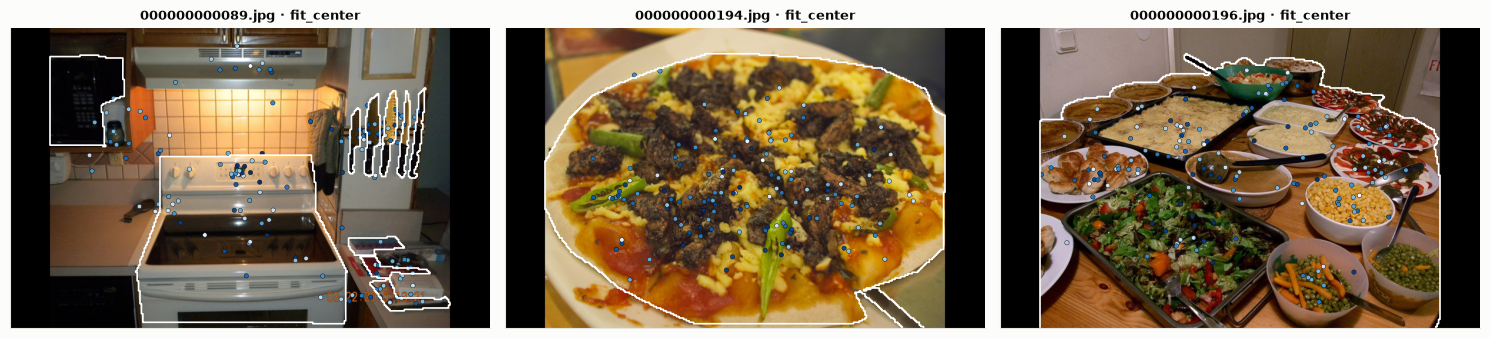

In [6]:
print(info["mode"].value_counts().to_dict())
print(f"alignment IoU: median {info.iou.median():.3f}, images below 0.95: {(info.iou < 0.95).sum()}")

ex = images[:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, name in zip(axes, ex):
    stim = np.asarray(Image.open(stim_index[name]).convert("RGB"))
    _, _, inf = fv.score_image(name, stim, coco, by_image[name], by_image[donor[name]], cmaps[name],
                               combine=COMBINE, keep_maps=True)
    ax.imshow(stim); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    up = np.kron(inf["glab"] >= 0, np.ones((fv.GRID_DS, fv.GRID_DS)))
    ax.contour(up, levels=[0.5], colors="#ffffff", linewidths=1.2)
    f = by_image[name]
    ax.scatter(f.x, f.y, s=10, c=f.idx, cmap="Blues_r", edgecolors="#0b0b0b", linewidths=0.3)
    ax.set_title(f"{name} · {inf['mode']}", fontsize=9)
plt.tight_layout(); plt.savefig("figures/01_alignment_check.png", dpi=140); plt.show()

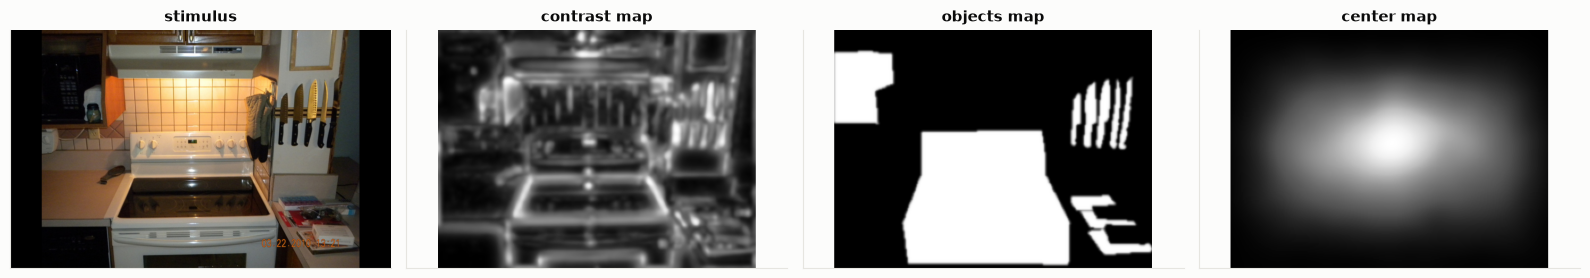

In [7]:
# What the three maps look like for one image (z-scored; padding blank)
name = ex[0]
stim = np.asarray(Image.open(stim_index[name]).convert("RGB"))
_, _, inf = fv.score_image(name, stim, coco, by_image[name], by_image[donor[name]], cmaps[name],
                           combine=COMBINE, keep_maps=True)
fig, axes = plt.subplots(1, 4, figsize=(16, 2.9))
axes[0].imshow(stim); axes[0].set_title("stimulus")
for ax, k in zip(axes[1:], ["contrast", "objects", "center"]):
    ax.imshow(inf["maps"][k], cmap="Greys_r"); ax.set_title(f"{k} map")
for ax in axes: ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig("figures/02_example_maps.png", dpi=140); plt.show()

## Analysis 1 · Do fixations land on objects, and does that change over time?
Three lines per index: share of fixations on any object (**own**), the same for fixations borrowed from another
image (**shuffled**), and the share of the image covered by objects (**area**, what uniformly random gaze would get).

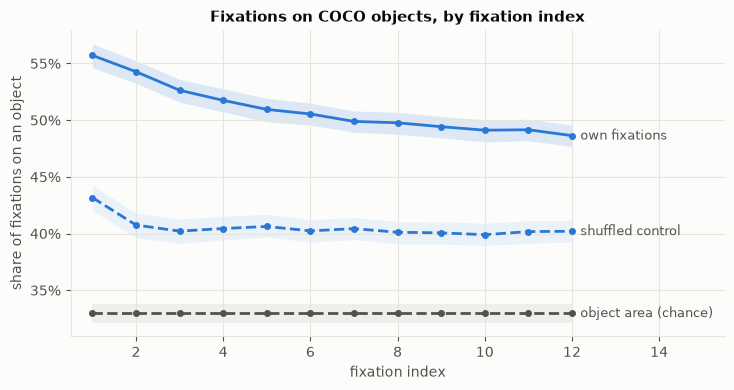

idx,1,2,3,4,5,6,7,8,9,10,11,12
own,0.557,0.543,0.526,0.517,0.509,0.505,0.499,0.498,0.494,0.491,0.492,0.486
shuffled,0.432,0.408,0.402,0.404,0.406,0.402,0.404,0.401,0.401,0.399,0.402,0.402
area,0.330,0.330,0.330,0.330,0.330,0.330,0.330,0.330,0.330,0.330,0.330,0.330


In [8]:
o = fv.bootstrap_by_index(own.assign(v=own.on_object.astype(float)), "v", MAX_IDX)
s = fv.bootstrap_by_index(shuf.assign(v=shuf.on_object.astype(float)), "v", MAX_IDX)
a = fv.bootstrap_by_index(own.assign(v=own.obj_area_frac), "v", MAX_IDX)

fig, ax = plt.subplots(figsize=(7.5, 4))
ci_line(ax, o, C["objects"], "own fixations")
ci_line(ax, s, C["objects"], "shuffled control", dashed=True)
ci_line(ax, a, INK2, "object area (chance)", dashed=True)
ax.set(xlabel="fixation index", ylabel="share of fixations on an object",
       title="Fixations on COCO objects, by fixation index", xlim=(0.5, MAX_IDX + 3.5))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.savefig(f"figures/10_object_hits_{TAG}.png", dpi=160); plt.show()
display(pd.DataFrame({"idx": o.idx, "own": o["mean"].round(3), "shuffled": s["mean"].round(3),
                      "area": a["mean"].round(3)}).set_index("idx").T)

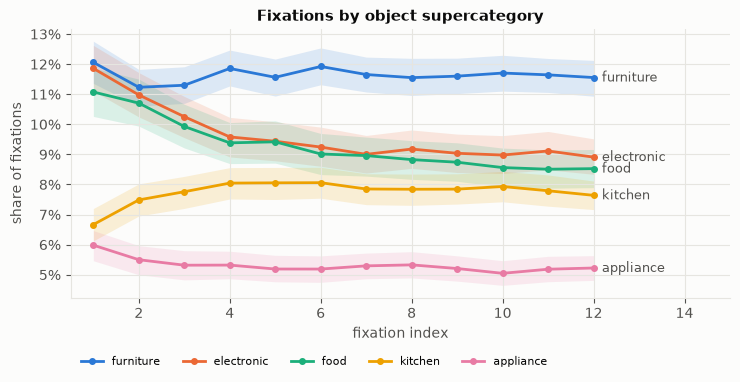

In [9]:
# Which kinds of objects? Share of fixations by COCO supercategory (top 5 overall).
top = own[own.on_object].supercat.value_counts().index[:5]
slots = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
fig, ax = plt.subplots(figsize=(7.5, 4))
for sc, col in zip(top, slots):
    d = fv.bootstrap_by_index(own.assign(v=(own.supercat == sc).astype(float)), "v", MAX_IDX)
    ci_line(ax, d, col, sc)
ax.set(xlabel="fixation index", ylabel="share of fixations", xlim=(0.5, MAX_IDX + 3),
       title="Fixations by object supercategory")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="upper left", ncol=5, fontsize=8, bbox_to_anchor=(0, -0.18))
plt.tight_layout(); plt.savefig(f"figures/11_supercategories_{TAG}.png", dpi=160); plt.show()

## Analysis 2 · Which map predicts fixation *k* best?
NSS = the z-scored map value at the fixated pixel (0 = chance, higher = better). Left: raw NSS for own fixations
(solid) and the shuffled control (dashed). Right: **own minus shuffled**, the image-specific part. The pattern
the question predicts is contrast relatively strong early and objects pulling ahead later, *on the right panel*.

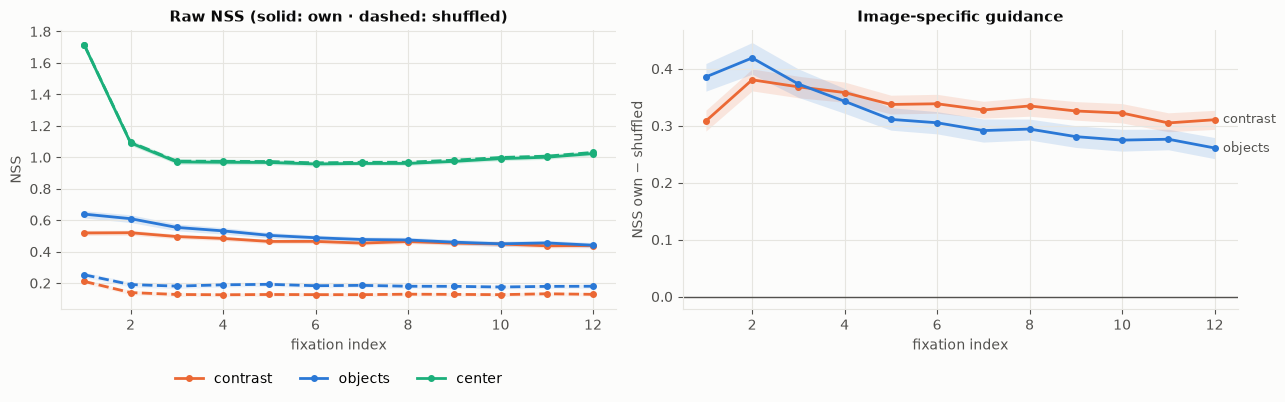

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for k in ["contrast", "objects", "center"]:
    d_own = fv.bootstrap_by_index(own, f"nss_{k}", MAX_IDX)
    d_sh = fv.bootstrap_by_index(shuf, f"nss_{k}", MAX_IDX)
    ci_line(ax1, d_own, C[k], k, end_label=False)            # legend instead: end labels collide
    ci_line(ax1, d_sh, C[k], None, dashed=True, end_label=False)
    if k == "center":
        continue  # the centre map is the same for every image, so own - shuffled is not meaningful
    # image-level difference, then bootstrap over images
    po = own.groupby(["map_image", "idx"])[f"nss_{k}"].mean()
    ps = shuf.groupby(["map_image", "idx"])[f"nss_{k}"].mean()
    diff = (po - ps).dropna().rename("v").reset_index()
    ci_line(ax2, fv.bootstrap_by_index(diff, "v", MAX_IDX), C[k], k)
ax1.set(xlabel="fixation index", ylabel="NSS", title="Raw NSS (solid: own · dashed: shuffled)",
        xlim=(0.5, MAX_IDX + 0.5))
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
ax2.axhline(0, color=INK2, lw=1)
ax2.set(xlabel="fixation index", ylabel="NSS own − shuffled", title="Image-specific guidance")
plt.tight_layout(); plt.savefig(f"figures/20_nss_by_index_{TAG}.png", dpi=160); plt.show()

## Analysis 2b · Does each map still predict gaze once the other is accounted for?
Objects tend to be high-contrast, so the two curves above partly carry the same signal. Here, for each fixation
index, a logistic regression separates **fixated** locations (own fixations) from **control** locations
(shuffled-control fixations on the same image, which share the centre bias but not the image content), with
both maps as predictors:

$$\text{logit}\,P(\text{fixated}) = b_0 + b_\text{contrast}\cdot\text{contrast} + b_\text{objects}\cdot\text{objects}$$

Both predictors are z-scored map values, so each coefficient is the change in log-odds per 1 SD of that map,
**holding the other map fixed**. A coefficient whose CI stays above 0 means that map adds information the other
one doesn't. CIs resample images. This takes a minute or two on the full dataset.

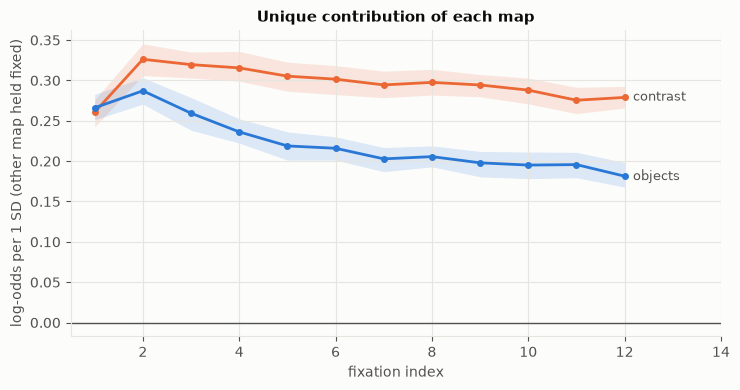

idx,1,2,3,4,5,6,7,8,9,10,11,12
map,,,,,,,,,,,,
contrast,0.261,0.326,0.320,0.316,0.305,0.302,0.294,0.298,0.294,0.288,0.275,0.279
objects,0.266,0.287,0.259,0.236,0.219,0.216,0.203,0.206,0.198,0.195,0.196,0.181


In [11]:
joint = fv.joint_by_index(own, shuf, MAX_IDX, n_boot=N_BOOT_JOINT, seed=SEED)
joint.to_csv(f"figures/21_joint_regression_{TAG}.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4))
for k in ["contrast", "objects"]:
    d = joint[joint["map"] == k].rename(columns={"coef": "mean"})
    ci_line(ax, d, C[k], k)
ax.axhline(0, color=INK2, lw=1)
ax.set(xlabel="fixation index", ylabel="log-odds per 1 SD (other map held fixed)",
       title="Unique contribution of each map", xlim=(0.5, MAX_IDX + 2))
plt.tight_layout(); plt.savefig(f"figures/21_joint_regression_{TAG}.png", dpi=160); plt.show()
display(joint.pivot(index="map", columns="idx", values="coef").round(3))

## Analysis 2c · Is the pattern consistent across observers?
One thin line per subject: the image-specific advantage of objects over contrast,
(objects own − shuffled) − (contrast own − shuffled), using NSS. Above 0 means objects predict that person's
fixation *k* better than contrast does. If the crossover is real, most lines should start above 0 and drift
below it; if one or two people drive it, it shows here.

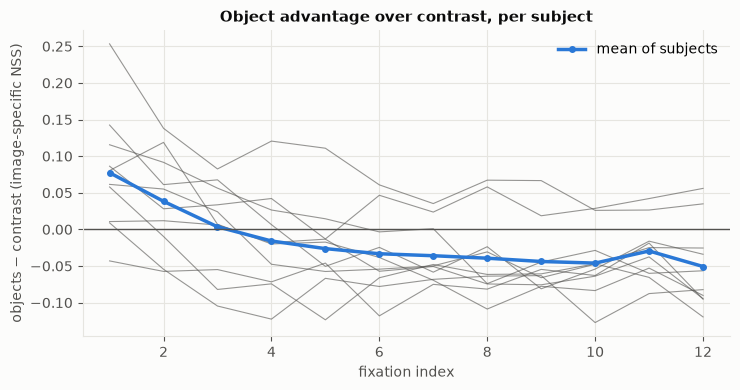

subjects with object advantage early (fix 1-2): 8/10 · late (fix 7-12): 2/10 · advantage shrinks from early to late in 10/10


In [12]:
base = shuf.groupby("idx")[["nss_objects", "nss_contrast"]].mean()   # shuffled baseline per index
per = own.groupby(["subject", "idx"])[["nss_objects", "nss_contrast"]].mean()
per = per.sub(base, level="idx")
adv = (per.nss_objects - per.nss_contrast).unstack("subject")

fig, ax = plt.subplots(figsize=(7.5, 4))
for s in adv.columns:
    ax.plot(adv.index, adv[s], color=INK2, lw=0.8, alpha=0.6)
ax.plot(adv.index, adv.mean(axis=1), color=C["objects"], lw=2.5, marker="o", ms=4, label="mean of subjects")
ax.axhline(0, color=INK2, lw=1)
ax.set(xlabel="fixation index", ylabel="objects − contrast (image-specific NSS)",
       title="Object advantage over contrast, per subject", xlim=(0.5, MAX_IDX + 0.5))
ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig(f"figures/22_per_subject_{TAG}.png", dpi=160); plt.show()
early, late = adv.loc[1:2].mean(), adv.loc[7:MAX_IDX].mean()
print(f"subjects with object advantage early (fix 1-2): {(early > 0).sum()}/{len(early)} · "
      f"late (fix 7-{MAX_IDX}): {(late > 0).sum()}/{len(late)} · "
      f"advantage shrinks from early to late in {(late < early).sum()}/{len(early)}")

## Analysis 3 · Saccade amplitude and fixation duration over time
A coarse look at whether viewing shifts from broad exploration (long saccades, short fixations) to local
inspection. With `PX_PER_DEG` set, amplitudes are in degrees of visual angle.

Durations exclude the **last fixation of each scanpath**: the 5-second trial ends mid-fixation, so its recorded duration is cut short, and late indices contain proportionally more of these.

durations: excluded 9,910 truncated last fixations of 497,139


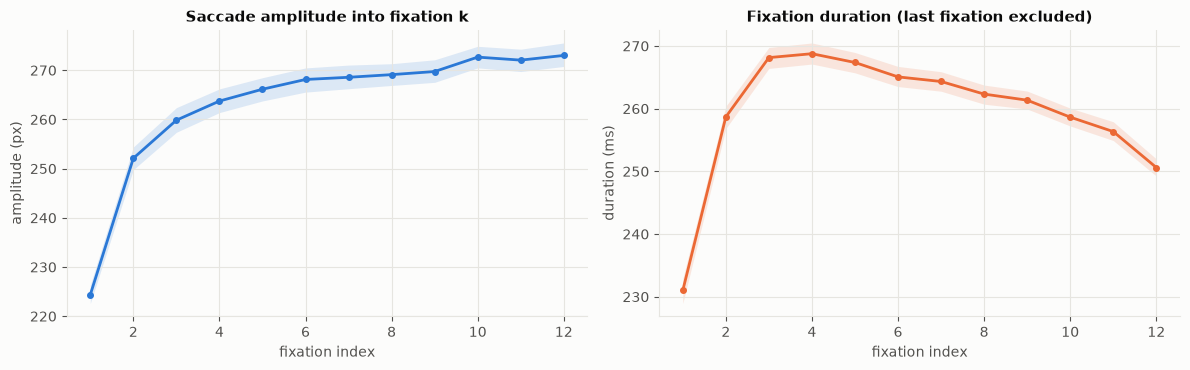

In [13]:
used_images = set(own.map_image)   # respects MAX_OBJ_FRAC
sac = raw[raw.image.isin(used_images) & (raw.idx >= 1) & (raw.idx <= MAX_IDX)].rename(columns={"image": "map_image"})
dur = sac[~sac.is_last]            # last fixation of each scanpath is truncated by the trial end
print(f"durations: excluded {sac.is_last.sum():,} truncated last fixations of {len(sac):,}")
amp = "amp_deg" if PX_PER_DEG else "amp_px"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ci_line(ax1, fv.bootstrap_by_index(sac, amp, MAX_IDX), C["objects"], "", end_label=False)
ax1.set(xlabel="fixation index", ylabel=f"amplitude ({'deg' if PX_PER_DEG else 'px'})",
        title="Saccade amplitude into fixation k")
ci_line(ax2, fv.bootstrap_by_index(dur, "dur", MAX_IDX), C["contrast"], "", end_label=False)
ax2.set(xlabel="fixation index", ylabel="duration (ms)", title="Fixation duration (last fixation excluded)")
plt.tight_layout(); plt.savefig(f"figures/30_saccades_durations_{TAG}.png", dpi=160); plt.show()

## Robustness runs
Each run below is the same notebook with one setting changed. Scoring is cached per `COMBINE` value, so the
filter runs only re-plot. Figures are saved with a tag (`max`, `mean`, `max_maxobj0.5`) so they don't overwrite
each other. Compare figures 20, 21 and 22 across runs.

| run | change in the setup cell | what it tests |
|---|---|---|
| main | `N_IMAGES = 0` | the result on all images (report this N) |
| A | `MAX_OBJ_FRAC = 0.5` | is it driven by images dominated by one big object? |
| B | `COMBINE = "mean"` | does the contrast result depend on how channels are combined? |

A pattern worth writing about should look the same in all three.

## Write-up notes

**What I found** (N = 4,317 images, 10 observers, fixations 1–12; 95% CIs resample images)
- **Analysis 1 (object hits):** About 56% of first fixations land on a COCO object, falling to about 50% by
  fixation 7 and then levelling off. The shuffled control stays flat at about [Z]%, and the object-area chance level is about 37.5%, so the image-specific pull toward objects shrinks over viewing. 
- **Analysis 2 (NSS by index):** After subtracting the shuffled control, object NSS peaks at fixation 2
  (≈0.42) and falls to ≈0.26 by fixation 12. Contrast NSS rises from ≈0.31 to ≈0.38 at fixation 2 and stays
  near ≈0.31–0.34 afterwards. The curves cross at fixation 3, and from about fixation 5 on, contrast predicts gaze better, with non-overlapping CIs. 
- **Analysis 2b (joint regression):** With both maps in the model, both coefficients stay above zero at every fixation, so each map adds information the other doesn't. At fixation 1 they're tied (contrast 0.26
  [0.24–0.28], objects 0.27 [0.25–0.28] log-odds per SD). From fixation 2, contrast leads. By fixation 12,
  contrast is 0.28 [0.27–0.29] and objects 0.18 [0.17–0.20]. From their peaks, objects' unique contribution
  falls by 37% and contrast's by 14%.
- **Analysis 2c (per subject):** At fixation 1, about 9 of 10 observers show an object advantage over contrast.
  By fixations 7–12, about 8 of 10 show a contrast advantage, while 2 keep a small object advantage throughout.
- **Analysis 3 (saccades, durations):** Incoming saccade amplitude rises from ≈224 px at fixation 1 to ≈273 px
  at fixation 12. Fixation duration (truncated last fixations excluded) rises from ≈231 ms to a peak of
  ≈269 ms at fixation 4, then declines to ≈250 ms. This is the opposite of a classic shift from exploratory to
  local viewing, and may partly reflect scanpath length (see limitations).
- **Robustness:**
  - (A) Excluding images where one object covers more than 50%: the pattern is unchanged. At fixation 12,
    contrast is 0.30 [0.28–0.31] and objects 0.18 [0.16–0.20].
  - (B) Averaging the contrast channels instead of taking the max: object results are identical, contrast is
    slightly stronger, and the NSS crossover moves earlier, from fixation 3 to fixation 2. At fixation 12,
    contrast is 0.28 [0.27–0.29] and objects 0.18 [0.17–0.20].

  Neither choice creates the effect.

**Limitations to state honestly**
- The contrast map is a simple low-level baseline, not a model of V1 or of any specific theory.
- COCO masks cover 80 labelled categories only. Unlabelled things people look at (text, papers, signs, parts)
  count as background, so a drift of gaze toward such details over time would look like declining object
  guidance.
- Later indices come only from scanpaths long enough to reach them, i.e. from observers making more, shorter
  fixations. Part of the change over time (and the duration and amplitude trends) may reflect this composition
  rather than viewing time. I did not test this; restricting every index to the same scanpaths would.
- The joint model separates the two maps only as well as they are measured. A better object or saliency map
  could change the balance.
- With 10 observers, the per-subject check is descriptive, not a population-level test.

**Possible next steps**
- Restrict the analysis to scanpaths with at least 13 fixations, to rule out the composition confound.
- Add text and part annotations (e.g. COCO-Text) to test the label-coverage explanation directly.
- Add a pretrained deep saliency model as a third predictor, and ask *when* it adds to the low-level baseline.
- Split by eccentricity of the saccade target: are far, peripherally selected targets more contrast-driven? This
  would connect the result to the central–peripheral dichotomy.